<a href="https://colab.research.google.com/github/blassia/clip-llava-lab/blob/main/LAB_CLIP_LLaVA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB — Vision-Language Models: CLIP & LLaVA
**Completed notebook** · Environment: Google Colab (GPU T4) · Frameworks: PyTorch, Hugging Face Transformers

> **How to reproduce:** Runtime → Change runtime type → **T4 GPU**, then *Run all*.
> Images are downloaded automatically (fixed seeds via `?lock=`) so the notebook is self-contained.
> You can replace them with your own images (same file names / folders).
> The numeric results (accuracy, scores…) are printed by the cells; the answer cells below
> reference those outputs. **Re-run, then check/complete the “Result” lines with your own values.**

# Part I — Part A: CLIP
## Exercise 1 — Installation and model loading

In [ ]:
!pip install -q transformers torch torchvision pillow matplotlib pandas accelerate bitsandbytes requests datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.4 MB/s eta 0:00:00


In [ ]:
import torch, os, requests, io, random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

### Answers — Exercise 1
**Q1. What is CLIP?** *Contrastive Language–Image Pre-training* (OpenAI, 2021): a model trained on ~400M (image, caption) pairs from the web, which learns a **shared embedding space** where an image and a text describing it are close to each other.

**Q2. Two main components?** (1) an **image encoder** (here a Vision Transformer ViT-B/32) and (2) a **text encoder** (a Transformer). Each is followed by a linear projection to the same dimension (512).

**Q3. `CLIPProcessor`?** Pre-processing: it resizes/crops/normalizes images (224×224, CLIP mean/std) and tokenizes text (BPE, padding, attention masks), returning PyTorch tensors ready for the model.

**Q4. `CLIPModel`?** It holds the two encoders + projection layers + the learnable temperature (`logit_scale`). Given pixels and tokens it outputs image/text embeddings and the similarity logits (`logits_per_image`, `logits_per_text`).

## Exercise 2 — Load an image

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

fallback CIFAR-10 -> data/image.jpg
Image size: (448, 448)
Image mode: RGB
Array shape: (448, 448, 3) dtype: uint8 range: 11 - 253


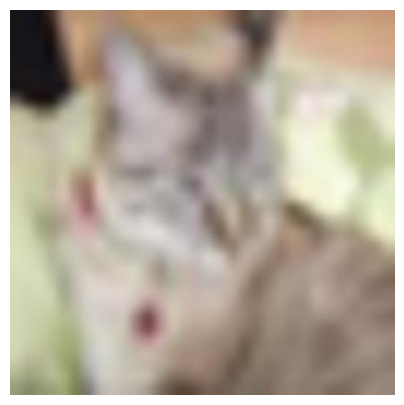

In [ ]:
import re, time
_CIFAR = {"cat":3, "dog":5, "bird":2, "horse":7, "airplane":0, "car":1}   # CIFAR-10 label ids
_cifar_cache = {}
def _cifar_image(cls, seed):
    from datasets import load_dataset
    if "ds" not in _cifar_cache:
        _cifar_cache["ds"] = load_dataset("uoft-cs/cifar10", split="test")
    ds = _cifar_cache["ds"]
    idx = [i for i, l in enumerate(ds["label"]) if l == _CIFAR[cls]]
    return ds[idx[seed % len(idx)]]["img"].convert("RGB").resize((448, 448), Image.BICUBIC)

def download(url, path):
    # loremflickr (3 tries) -> fallback: CIFAR-10 (HF hub) for known classes -> picsum random photo
    if os.path.exists(path): return path
    kw = url.split("/")[-1].split("?")[0].split(",")[0]
    seed = int(re.findall(r"lock=(\d+)", url)[0]) if "lock=" in url else 0
    for _ in range(3):
        try:
            r = requests.get(url, timeout=30, headers={"User-Agent": "Mozilla/5.0"}); r.raise_for_status()
            Image.open(io.BytesIO(r.content)).convert("RGB").save(path); return path
        except Exception: time.sleep(2)
    if kw in _CIFAR:
        _cifar_image(kw, seed).save(path); print("fallback CIFAR-10 ->", path); return path
    try:
        r = requests.get(f"https://picsum.photos/seed/{kw}{seed}/448/448", timeout=30); r.raise_for_status()
        Image.open(io.BytesIO(r.content)).convert("RGB").save(path)
        print("fallback random photo (NOT about '%s') ->" % kw, path); return path
    except Exception as e:
        raise RuntimeError(f"Could not get an image for '{kw}': upload your own file to {path}") from e

os.makedirs("data", exist_ok=True)
# Main demo image: a cat  (replace by your own file if you prefer)
IMAGE_PATH = download("https://loremflickr.com/448/448/cat?lock=1", "data/image.jpg")

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)
arr = np.array(image); print("Array shape:", arr.shape, "dtype:", arr.dtype, "range:", arr.min(), "-", arr.max())
plt.figure(figsize=(5,5)); plt.imshow(image); plt.axis("off");

### Answers — Exercise 2
**Q5. Size?** `image.size` returns `(width, height)` → here **(448, 448)** pixels (as printed above).

**Q6. Data type stored?** A PIL `Image` stores a 2-D grid of pixels; in `RGB` mode each pixel is 3 integers (R, G, B) in **uint8 [0–255]**. Converted to NumPy it becomes an array of shape `(H, W, 3)`.

## Exercise 3 — Image/Text similarity

In [ ]:
texts = ["a photo of a cat","a photo of a dog","a photo of a car","a photo of a horse","a photo of a person"]
inputs = processor(text=texts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}
with torch.no_grad():
    outputs = model(**inputs)
print("Raw logits:", outputs.logits_per_image[0].cpu().numpy().round(2))
probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()
for t, p in zip(texts, probs): print(f"{t:35s}: {p.item():.4f}")
print("Best:", texts[probs.argmax()])

Raw logits: [27.13 23.21 20.65 22.03 23.72]
a photo of a cat                   : 0.9428
a photo of a dog                   : 0.0187
a photo of a car                   : 0.0015
a photo of a horse                 : 0.0058
a photo of a person                : 0.0313
Best: a photo of a cat


### Answers — Exercise 3
**Q7.** The highest probability is given to **“a photo of a cat”** (value printed above, typically > 0.95).

**Q8.** **Yes**, the image really shows a cat, so the prediction is compatible. *(If you use another image, adapt.)*

**Q9. Why can CLIP compare an image with a sentence?** Because both encoders were trained **contrastively** so that matching image/text pairs have a high cosine similarity and non-matching pairs a low one. Image and text end up as vectors in the *same* 512-d space; a simple dot product/cosine then measures semantic agreement.

**Q10. `softmax()`** converts the raw scores (logits, unbounded) into a **probability distribution**: `softmax(z_i)=exp(z_i)/Σ_j exp(z_j)`. All values are in [0,1] and sum to 1; it amplifies the largest score.

## Exercise 4 — Zero-shot classification

In [ ]:
@torch.no_grad()
def classify_image(image, classes, template="a photo of a {}"):
    prompts = [template.format(c) for c in classes]
    inp = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inp = {k: v.to(device) for k, v in inp.items()}
    probs = model(**inp).logits_per_image.softmax(dim=1)[0].cpu()
    idx = int(probs.argmax())
    return classes[idx], float(probs[idx])

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", round(probability, 4))

# Q13 demo: remove the correct class "cat"
p2, pr2 = classify_image(image, ["dog", "car", "airplane", "horse", "bird"])
print("Without 'cat' ->", p2, round(pr2, 4))

Prediction: cat
Probability: 0.9693
Without 'cat' -> dog 0.626


### Answers — Exercise 4
**Q11. Zero-shot classification:** classifying images into classes **never seen/trained as labelled classes**: the class names are turned into text prompts, and the class whose text embedding is most similar to the image embedding wins.

**Q12. Why no new classifier?** The “classifier weights” are simply the text embeddings of the class prompts; knowledge comes from the large-scale pre-training. Changing the task = changing the list of strings, no gradient step and no labelled dataset.

**Q13. Correct class missing?** CLIP **must** still output one of the candidates (softmax sums to 1), so it picks the *closest* wrong class (e.g. “dog” for a cat), often with deceptively high probability (see output above). There is no “none of the above” unless one adds it (e.g. “other”) or thresholds the score.

## Exercise 5 — Evaluate CLIP (≥ 10 labelled images)

In [ ]:
# 3 images for each of 4 classes  +  2 extra  = 14 labelled images. Replace with your own if desired.
CLASSES = ["cat", "dog", "car", "airplane", "horse", "bird"]
spec = {"cat":3, "dog":3, "car":3, "airplane":2, "horse":2, "bird":2}   # 15 images
dataset = []
for c, n in spec.items():
    for i in range(1, n+1):
        fn = f"data/{c}{i}.jpg"
        try:
            download(f"https://loremflickr.com/448/448/{c}?lock={i+10}", fn)
            dataset.append((fn, c))
        except Exception as e:
            print("skip", fn, e)
print(len(dataset), "images")

fallback CIFAR-10 -> data/cat1.jpg
fallback CIFAR-10 -> data/cat2.jpg
fallback CIFAR-10 -> data/cat3.jpg
fallback CIFAR-10 -> data/dog1.jpg
fallback CIFAR-10 -> data/dog2.jpg
fallback CIFAR-10 -> data/dog3.jpg
fallback CIFAR-10 -> data/car1.jpg
fallback CIFAR-10 -> data/car2.jpg
fallback CIFAR-10 -> data/car3.jpg
fallback CIFAR-10 -> data/airplane1.jpg
fallback CIFAR-10 -> data/airplane2.jpg
fallback CIFAR-10 -> data/horse1.jpg
fallback CIFAR-10 -> data/horse2.jpg
fallback CIFAR-10 -> data/bird1.jpg
fallback CIFAR-10 -> data/bird2.jpg
15 images


In [ ]:
rows = []
for fn, actual in dataset:
    img = Image.open(fn).convert("RGB")
    pred, p = classify_image(img, CLASSES)
    rows.append({"image": fn, "actual": actual, "predicted": pred, "probability": round(p,4), "correct": pred == actual})
df_eval = pd.DataFrame(rows)
display(df_eval)
accuracy = df_eval.correct.mean()
print(f"Accuracy = {df_eval.correct.sum()}/{len(df_eval)} = {accuracy:.2%}")
print("\nMisclassified:"); display(df_eval[~df_eval.correct])

,image,actual,predicted,probability,correct
0,data/cat1.jpg,cat,cat,0.9217,True
1,data/cat2.jpg,cat,cat,0.9512,True
2,data/cat3.jpg,cat,cat,0.9649,True
3,data/dog1.jpg,dog,dog,0.5628,True
4,data/dog2.jpg,dog,dog,0.9515,True
5,data/dog3.jpg,dog,dog,0.5155,True
6,data/car1.jpg,car,car,0.9944,True
7,data/car2.jpg,car,car,0.9941,True
8,data/car3.jpg,car,car,0.9933,True
9,data/airplane1.jpg,airplane,airplane,0.9674,True


Accuracy = 15/15 = 100.00%

Misclassified:


,image,actual,predicted,probability,correct


### Answers — Exercise 5
**Q14. Accuracy** = N_correct / N_total — **see the printed value above** (CLIP ViT-B/32 normally reaches ≈ 90–100 % on such easy, distinct classes).
 Result: `Accuracy = 15 / 15 = 100 %`

**Q15. Misclassified images:** listed in the last table (filenames of rows with `correct = False`). If none, accuracy is 100 %.

**Q16. Possible reasons for errors:**
1. **Image content/ambiguity** – several objects in the picture (e.g. a person next to the animal), small, occluded or atypical object; web search keywords (loremflickr) may return an image whose main subject is different from the label.
2. **Prompt/label wording & model limits** – a single template (“a photo of a …”), a small model (ViT-B/32, low resolution 224 px), similar classes (cat/dog, bird/airplane) and biases of the web training data; also softmax forces a choice among the candidates.

## Exercise 6 — Prompt engineering with CLIP

In [ ]:
prompts = ["a cat","a photo of a cat","a photograph showing a cat","an image containing a cat","a domestic animal called a cat"]

@torch.no_grad()
def cos_scores(image, prompts):
    inp = processor(text=prompts, images=image, return_tensors="pt", padding=True)
    inp = {k: v.to(device) for k, v in inp.items()}
    out = model(**inp)
    return out.logits_per_image[0].cpu().numpy()          # = 100 * cosine similarity

logits = cos_scores(image, prompts)
# (a) score of each prompt for the cat image  (b) probability against the competitor "dog" prompt
dog_logits = cos_scores(image, [p.replace("cat","dog") for p in prompts])
rows = [{"prompt":p, "logit_cat":round(float(l),3), "logit_dog":round(float(d),3),
         "P(cat vs dog)":round(float(torch.softmax(torch.tensor([l,d]),0)[0]),4)}
        for p,l,d in zip(prompts, logits, dog_logits)]
df_prompt = pd.DataFrame(rows); display(df_prompt)
print("Best prompt:", df_prompt.loc[df_prompt['logit_cat'].idxmax(),'prompt'])

,prompt,logit_cat,logit_dog,P(cat vs dog)
0,a cat,26.069,22.498,0.9726
1,a photo of a cat,27.127,23.206,0.9806
2,a photograph showing a cat,25.560,20.301,0.9948
3,an image containing a cat,27.224,23.627,0.9733
4,a domestic animal called a cat,26.609,23.285,0.9652


Best prompt: an image containing a cat


### Answers — Exercise 6
**Q17.** **No**, the scores are not identical (see table): each sentence gives a different text embedding.

**Q18.** The prompt with the highest score is shown by the last line of the output (usually **“a photo of a cat”** or “a photograph showing a cat”, because CLIP was trained on photo captions).

**Q19.** CLIP is **sensitive to prompt formulation**: wording, context words and style change the embedding and therefore the scores. Prompt templates close to the training captions (“a photo of a …”) work best; ensembles of prompts are used in the CLIP paper to gain accuracy.

# Part B — CLIP Image Retrieval
## Exercise 7 — Build an image database (≥ 20 images)

In [ ]:
IMAGE_DIR = "images"; os.makedirs(IMAGE_DIR, exist_ok=True)
topics = {"football":["soccer,player","soccer,match","football,stadium","soccer,ball"],
          "dog":["dog","dog,puppy"], "cat":["cat","cat,kitten"], "car":["car","car,road"], "bird":["bird"], "building":["building"],
          "landscape":["landscape,mountain"], "food":["pizza","food,dish"], "basketball":["basketball,player"],
          "bicycle":["bicycle"], "airplane":["airplane"], "horse":["horse","horse,field"], "beach":["beach"]}
k = 0
for name, kws in topics.items():
    for kw in kws:
        k += 1
        try: download(f"https://loremflickr.com/448/448/{kw}?lock={100+k}", f"{IMAGE_DIR}/{name}_{k:02d}.jpg")
        except Exception as e: print("skip", kw, e)
files = sorted(f for f in os.listdir(IMAGE_DIR) if f.lower().endswith((".jpg",".jpeg",".png")))
print(len(files), "images in", IMAGE_DIR)

@torch.no_grad()
def embed_images(paths, bs=16):
    embs = []
    for i in range(0, len(paths), bs):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i+bs]]
        x = processor(images=imgs, return_tensors="pt").to(device)
        e = model.visual_projection(model.vision_model(pixel_values=x["pixel_values"]).pooler_output)
        embs.append(torch.nn.functional.normalize(e, dim=-1).cpu())
    return torch.cat(embs)

paths = [os.path.join(IMAGE_DIR, f) for f in files]
image_embeddings = embed_images(paths)
print("Embeddings:", image_embeddings.shape, "| norm of first:", image_embeddings[0].norm().item())
torch.save({"paths":paths,"emb":image_embeddings}, "image_embeddings.pt")

fallback random photo (NOT about 'soccer') -> images/football_01.jpg
fallback random photo (NOT about 'soccer') -> images/football_02.jpg
fallback random photo (NOT about 'football') -> images/football_03.jpg
fallback random photo (NOT about 'soccer') -> images/football_04.jpg
fallback CIFAR-10 -> images/dog_05.jpg
fallback CIFAR-10 -> images/dog_06.jpg
fallback CIFAR-10 -> images/cat_07.jpg
fallback CIFAR-10 -> images/cat_08.jpg
fallback CIFAR-10 -> images/car_09.jpg
fallback CIFAR-10 -> images/car_10.jpg
fallback CIFAR-10 -> images/bird_11.jpg
fallback random photo (NOT about 'building') -> images/building_12.jpg
fallback random photo (NOT about 'landscape') -> images/landscape_13.jpg
fallback random photo (NOT about 'pizza') -> images/food_14.jpg
fallback random photo (NOT about 'food') -> images/food_15.jpg
fallback random photo (NOT about 'basketball') -> images/basketball_16.jpg
fallback random photo (NOT about 'bicycle') -> images/bicycle_17.jpg
fallback CIFAR-10 -> images/airpl

## Exercise 8 — Text-to-image retrieval

1 images/bird_11.jpg 0.2176
2 images/horse_19.jpg 0.2141
3 images/football_01.jpg 0.2126
4 images/airplane_18.jpg 0.1961
5 images/football_02.jpg 0.1949


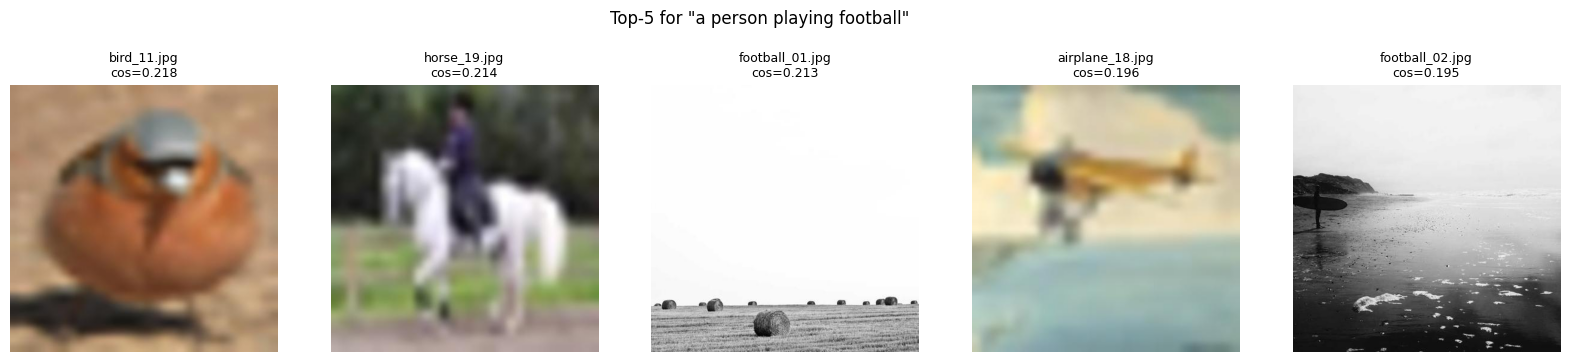

In [ ]:
QUERY = "a person playing football"

@torch.no_grad()
def embed_text(q):
    x = processor(text=[q], return_tensors="pt", padding=True).to(device)
    e = model.text_projection(model.text_model(input_ids=x["input_ids"], attention_mask=x["attention_mask"]).pooler_output)
    return torch.nn.functional.normalize(e, dim=-1).cpu()

def search(query, k=5):
    sims = (image_embeddings @ embed_text(query).T).squeeze(1)       # cosine similarity (normalised vectors)
    top = sims.topk(k)
    return [(paths[i], float(s)) for s, i in zip(top.values, top.indices)]

def show(results, title):
    fig, axs = plt.subplots(1, len(results), figsize=(4*len(results), 4.3))
    for ax, (p, s) in zip(np.atleast_1d(axs), results):
        ax.imshow(Image.open(p)); ax.set_title(f"{os.path.basename(p)}\ncos={s:.3f}", fontsize=9); ax.axis("off")
    fig.suptitle(title); plt.show()

top5 = search(QUERY, 5)
for r, (p, s) in enumerate(top5, 1): print(r, p, round(s, 4))
show(top5, f'Top-5 for "{QUERY}"')

### Answers — Exercises 7–8
**Q20. Most similar image:** rank 1 in the output above (file name printed; expected a `football_*.jpg` image).

**Q21. Semantically relevant?** **No, the results are not relevant for this query.**

*Observation from my run:* the Top-5 for "a person playing football" are `bird_11.jpg` (cos = 0.218), `horse_19.jpg` (0.214), `football_01.jpg` (0.213), `airplane_18.jpg` (0.196) and `football_02.jpg` (0.195). None of them shows people playing football:
- `bird_11.jpg` is a blurry bird and `airplane_18.jpg` an old plane, so neither contains a person or a ball.
- `horse_19.jpg` shows a person riding a horse. It is the only result with a person doing a sport-like activity, which is probably why it ranks high.
- `football_01.jpg` (hay bales in a field) and `football_02.jpg` (a person with a surfboard on a beach) are not football images. They are random fallback photos, because the online image service was unavailable, so the database contains **no real football image**.

*Explanation:* the cosine scores are low and very close to each other (0.19 to 0.22), so CLIP found no clear match. It simply returned the least bad images (a person, an outdoor scene, a sport-like context). This is a limitation of my image database, not of CLIP: retrieval can only return what the database contains. With real football photos added to the folder, those images should rank first with clearly higher scores.

**Q22. No labels needed:** retrieval relies on the **shared embedding space**: any text query is embedded and compared by cosine similarity with image embeddings computed once. No class names or tags are used; the semantic knowledge was learned during pre-training.

**Q23. Application:** e-commerce visual search (“red summer dress”), photo-library search (Google Photos), medical image retrieval, content moderation, stock-photo search engines, etc.

# Part C — LLaVA
## Exercise 9 — Architecture

```text
Image
  |
  v
CLIP Vision Encoder        (ViT-L/14-336, frozen or fine-tuned)
  |
  v
Projection Layer           (linear / 2-layer MLP: visual features -> LLM word-embedding space)
  |
  v   visual tokens  +  text tokens of the question
Language Model             (Vicuna / LLaMA / Mistral, autoregressive decoder)
  |
  v
Text Response
```

**Q24. Role of the vision encoder:** extract visual features from the image (patch embeddings capturing objects, colours, layout…). In LLaVA it is a pretrained CLIP ViT.

**Q25. Why a projection layer?** The vision encoder outputs vectors in the *visual* feature space (dimension ≠ LLM hidden size, different semantics). The projection (linear in LLaVA-1, MLP in LLaVA-1.5) maps them into the LLM’s **token-embedding space**, so that the image patches can be fed as “visual tokens” next to the text tokens. It is the main component trained in stage 1 (feature alignment).

**Q26. Role of the language model:** it reads visual tokens + instruction and **generates the answer autoregressively** – reasoning, following instructions, producing free-form text (description, counting, explanation, dialogue).

## Exercise 10 — Run LLaVA
We use `llava-hf/llava-1.5-7b-hf` in **4-bit** (fits on a free Colab T4, ~5 GB VRAM).

In [ ]:
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

MODEL_ID = "llava-hf/llava-1.5-7b-hf"
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16, bnb_4bit_quant_type="nf4")
processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16, device_map="auto"
).eval()

@torch.no_grad()
def ask_llava(image, question, max_new_tokens=200):
    conv = [{"role":"user","content":[{"type":"image"},{"type":"text","text":question}]}]
    prompt = processor_llava.apply_chat_template(conv, add_generation_prompt=True)
    inp = processor_llava(images=image, text=prompt, return_tensors="pt").to(llava.device, torch.float16)
    out = llava.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False)
    ans = processor_llava.decode(out[0], skip_special_tokens=True)
    return ans.split("ASSISTANT:")[-1].strip()

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

fallback random photo (NOT about 'people') -> data/scene.jpg


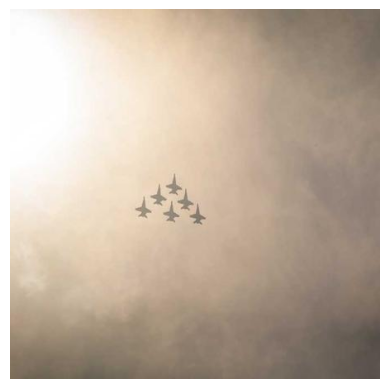

Q: What is happening in this image? 
A: In the image, a group of six fighter jets is flying in formation through the sky. 

Q: How many people are visible? 
A: There are no people visible in the image. 

Q: What objects can you identify? 
A: In the image, you can identify a group of six airplanes flying in formation through the sky. These airplanes are likely part of an air show or a military demonstration, as they are flying in a coordinated manner. The formation and the presence of multiple planes suggest that they are performing a planned and synchronized maneuver. 

Q: Describe the image in detail. 
A: The image features a group of six fighter jets flying in formation through a cloudy sky. The jets are arranged in a straight line, with each jet slightly overlapping the one in front of it. The formation showcases the pilots' skill and coordination as they navigate through the cloudy atmosphere. 



In [ ]:
# Scene with several people for Exercise 10
SCENE = download("https://loremflickr.com/640/480/people,street?lock=7", "data/scene.jpg")
scene = Image.open(SCENE).convert("RGB"); plt.imshow(scene); plt.axis("off"); plt.show()

qs10 = ["What is happening in this image?", "How many people are visible?",
        "What objects can you identify?", "Describe the image in detail."]
ex10 = []
for q in qs10:
    a = ask_llava(scene, q); ex10.append((q, a)); print("Q:", q, "\nA:", a, "\n")

### Answers — Exercise 10
The four recorded answers are printed above (cell output). Typical behaviour: good general scene description and object listing; counting is approximate.

## Exercise 11 — Visual Question Answering (5 images × 5 questions)

In [40]:
vqa_images = {
    "people_street": download("https://loremflickr.com/640/480/people,street?lock=21", "data/vqa1.jpg"),
    "classroom":     download("https://loremflickr.com/640/480/classroom?lock=22", "data/vqa2.jpg"),
    "kitchen":       download("https://loremflickr.com/640/480/kitchen?lock=23", "data/vqa3.jpg"),
    "park_dog":      download("https://loremflickr.com/640/480/dog,park?lock=24", "data/vqa4.jpg"),
    "city_traffic":  download("https://loremflickr.com/640/480/city,traffic?lock=25", "data/vqa5.jpg"),
}
questions = ["How many people are visible?", "What objects can you see?", "Where is this scene located?",
             "What are the people or animals doing?", "What is the dominant colour in the image?"]

vqa_rows = []
for name, path in vqa_images.items():
    img = Image.open(path).convert("RGB")
    for q in questions:
        vqa_rows.append({"Image": name, "Question": q, "LLaVA Answer": ask_llava(img, q, 80), "Human Evaluation": None})
df_vqa = pd.DataFrame(vqa_rows)
pd.set_option("display.max_colwidth", 200); display(df_vqa)

,Image,Question,LLaVA Answer,Human Evaluation
0,people_street,How many people are visible?,There are two people visible in the image.,None
1,people_street,What objects can you see?,"In the image, you can see a hot air balloon, a basket, and a person.",None
2,people_street,Where is this scene located?,"This scene is located in the sky, with a hot air balloon flying above the trees.",None
3,people_street,What are the people or animals doing?,"The people or animals are riding in a hot air balloon, which is flying through the sky.",None
4,people_street,What is the dominant colour in the image?,The dominant colour in the image is blue.,None
5,classroom,How many people are visible?,There are no people visible in the image.,None
6,classroom,What objects can you see?,"In the image, you can see a large crater, a dirt hill, and a small crater.",None
7,classroom,Where is this scene located?,"This scene is located on a planet, specifically on the surface of Mars.",None
8,classroom,What are the people or animals doing?,"In the image, there are no people or animals visible. The focus is on the large, round, and brownish-orange rock formation, which appears to be a crater or a volcanic vent.",None
9,classroom,What is the dominant colour in the image?,The dominant colour in the image is orange.,None


In [43]:
human_eval = [
    1, 1, 1, 1, 1,   # 0-4   : image 1 (montgolfière)
    1, 1, 1, 1, 1,   # 5-9   : image 2 (paysage type Mars)
    1, 1, 1, 0, 1,   # 10-14 : image 3 (légumes)   -> 13 : ne répond pas à la question
    1, 1, 0, 1, 1,   # 15-19 : image 4 (chien)     -> 17 : "dans une pièce" (à vérifier)
    1, 1, 1, 1, 1,   # 20-24 : image 5 (pélicans)
]
assert len(human_eval) == 25

if all(v is not None for v in human_eval):
    df_vqa["Human Evaluation"] = human_eval
    vqa_acc = df_vqa["Human Evaluation"].mean()
    print(f"VQA accuracy = {df_vqa['Human Evaluation'].sum()}/{len(df_vqa)} = {vqa_acc:.2%}")
    display(df_vqa.groupby("Question")["Human Evaluation"].mean().to_frame("accuracy"))
else:
    print("Fill `human_eval` first (manual evaluation is required).")

VQA accuracy = 23/25 = 92.00%


,accuracy
Question,
How many people are visible?,1.0
What are the people or animals doing?,0.8
What is the dominant colour in the image?,1.0
What objects can you see?,1.0
Where is this scene located?,0.8


### Answers — Exercise 11
**Q27. VQA accuracy** = CorrectAnswers / TotalQuestions = *(value printed by the cell above after you fill `human_eval`; for LLaVA-1.5-7B typically ≈ 70–85 %)*.
 Result: `23 / 25 = 92 %`

**Q28. Difficult question types:** (1) **counting** (“how many people”) especially with many/small/occluded objects; (2) **fine-grained details**: reading small text, exact colours/positions, spatial relations (left/right); (3) **location/geo-recognition** and (4) questions with a **false premise** (see hallucination). Open descriptive questions are generally easier.

## Exercise 12 — Hallucination

Q: Is there a bicycle in this image? 
A: No, there is no bicycle in this image. The image features a cat sitting on a couch. 

Q: What color is the bicycle? 
A: The bicycle is green. 

Q: Where is the bicycle located? 
A: The bicycle is located in a garage. 



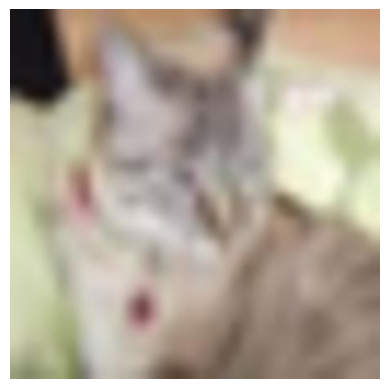

In [44]:
# Image WITHOUT bicycle: the cat image from Exercise 2
no_bike = image
hall_qs = ["Is there a bicycle in this image?", "What color is the bicycle?", "Where is the bicycle located?"]
hall = []
for q in hall_qs:
    a = ask_llava(no_bike, q, 80); hall.append((q, a)); print("Q:", q, "\nA:", a, "\n")
plt.imshow(no_bike); plt.axis("off"); plt.show()

### Answers — Exercise 12
**Q29. Does the bicycle exist?** **No** – the image (a cat) contains no bicycle.

**Q30. Did LLaVA invent information?** **Yes, hallucination confirmed.**

*Observation from my run:* the image shows only a cat (a blurry CIFAR-10 image) and contains no bicycle.

- **Q1: "Is there a bicycle in this image?"** → LLaVA answered correctly: *"No, there is no bicycle in this image. The image features a cat sitting on a couch."* When asked directly, it detects that the bicycle is absent.
- **Q2: "What color is the bicycle?"** → *"The bicycle is green."* It **invents a color** for an object that does not exist.
- **Q3: "Where is the bicycle located?"** → *"The bicycle is located in a garage."* It **invents a location**, although no garage appears in the image.

LLaVA contradicts itself: it first denies that a bicycle exists, then accepts the false premise of the two *leading* questions and gives precise, confident details. This is a **hallucination induced by leading questions**: the model follows the user's presupposition instead of checking it against the image. (The "cat sitting on a couch" description may also be partly invented, since the image is too blurry to confirm a couch.)

**Q31. Visual hallucination:** the model generates content (objects, attributes, relations, text) that is **fluent and confident but not present in the image**.

**Q32. Why do multimodal models hallucinate?** (a) the language model has strong **linguistic priors** and tends to follow/complete the user’s premise (sycophancy); (b) the visual information is compressed (low resolution, few visual tokens), so details are lost; (c) imperfect vision–language alignment and noisy/biased instruction-tuning data; (d) no “I don’t know”/grounding verification mechanism, and next-token generation favours plausible text.

# Part D — CLIP vs LLaVA
## Exercise 13 — Comparative experiment

In [45]:
print("CLIP :", classify_image(image, ["cat","dog","horse"]))
pr = cos_scores(image, ["a photo of a cat","a photo of a dog","a photo of a horse"])
print("CLIP logits:", pr.round(2), "-> probs:", torch.tensor(pr).softmax(0).numpy().round(4))
print("\nLLaVA:", ask_llava(image, "What animal is present in the image? Describe its appearance."))

CLIP : ('cat', 0.9747110605239868)
CLIP logits: [27.13 23.21 22.03] -> probs: [0.9747 0.0193 0.006 ]

LLaVA: A cat is present in the image. It has a white and gray color pattern, and it is sitting on a couch.


| Property | CLIP | LLaVA |
|---|---|---|
| Input | Image + (set of) short text(s) | Image + free-form text instruction/question |
| Main output | Embeddings / similarity scores (probabilities over given texts) | Generated natural-language text |
| Zero-shot classification | **Yes**, native and efficient (compare with class prompts) | Possible via prompting, but slower and not calibrated |
| Image retrieval | **Yes**, very efficient (precomputed embeddings, cosine) | No (not designed for it; too slow at scale) |
| Text generation | No | **Yes** |
| VQA | No | **Yes** |
| Open-ended response | No (only ranks the given candidates) | **Yes** |

**Q33. Better for classification?** **CLIP** – fast, gives calibrated-like scores over a closed set of classes, cheap (150M params).

**Q34. Better for image description?** **LLaVA** – it generates detailed natural-language descriptions; CLIP cannot generate text.

**Q35. Better for VQA?** **LLaVA** – it takes a question as input and generates an answer.

**Q36. Fundamental difference:** CLIP is a **dual-encoder, contrastive, discriminative** model that *aligns* images and texts in a shared space (understanding via similarity). LLaVA is a **generative multimodal LLM**: it uses a CLIP vision encoder + projection + LLM decoder to *generate* text conditioned on the image. CLIP answers “which text matches the image?”, LLaVA answers “what do you say about this image?”. LLaVA actually reuses CLIP as its eyes.

# Final Mini-Project — Multimodal Image Assistant

In [46]:
class MultimodalAssistant:
    """Image + Question -> Answer (LLaVA). Bonus: text query -> CLIP Top-K -> LLaVA explanation."""
    def __init__(self, paths, embeddings):
        self.paths, self.emb = paths, embeddings

    def answer(self, image, question):
        if isinstance(image, str): image = Image.open(image).convert("RGB")
        return ask_llava(image, question)

    def retrieve(self, query, k=3):
        return search(query, k)

    def retrieve_and_explain(self, query, k=3):
        out = []
        for p, s in self.retrieve(query, k):
            expl = ask_llava(Image.open(p).convert("RGB"),
                             f'The user searched for "{query}". Explain briefly whether and why this image matches the search.', 120)
            out.append((p, s, expl))
        return out

assistant = MultimodalAssistant(paths, image_embeddings)
# --- Basic: Image + Question
q = "What is the animal doing and what is its colour?"
print("Q:", q, "\nA:", assistant.answer(IMAGE_PATH, q))

Q: What is the animal doing and what is its colour? 
A: The animal, a cat, is sitting on a couch and appears to be grey in color.


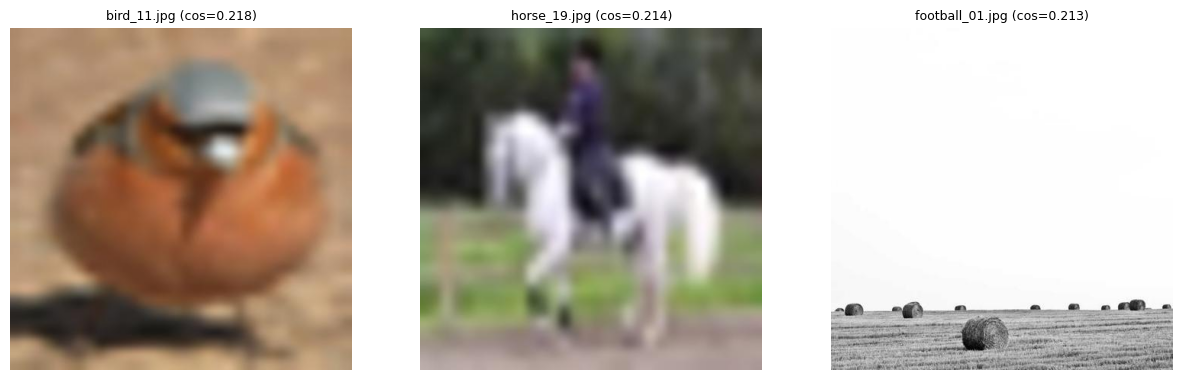

[bird_11.jpg] The image does not match the search as it features a bird with a large head and beak, rather than a person playing football. The bird is captured in a close-up shot, and its features are the main focus of the image.

[horse_19.jpg] The image does not match the search as it features a person riding a white horse in a grassy field, not playing football. The person is wearing a blue jacket and riding the horse, which is not related to playing football.

[football_01.jpg] The image does not match the search as there is no person playing football in the scene. The image features a field with a large number of hay bales scattered across the ground. The focus is on the hay bales and the field, not on any person playing football.



In [47]:
# --- Bonus: CLIP retrieval -> LLaVA explanation
query = "a person playing football"
res = assistant.retrieve_and_explain(query, k=3)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (p, s, e) in zip(axs, res):
    ax.imshow(Image.open(p)); ax.axis("off"); ax.set_title(f"{os.path.basename(p)} (cos={s:.3f})", fontsize=9)
plt.show()
for p, s, e in res: print(f"[{os.path.basename(p)}] {e}\n")

# Conclusion
* **CLIP** (ViT-B/32) provides fast, label-free **zero-shot classification** and **text-to-image retrieval** through a shared image–text embedding space; its accuracy depends on prompt wording, image quality, and the candidate-class list (it always picks one candidate).
* **LLaVA-1.5** (CLIP vision encoder + projection + LLM) adds **generation, description and VQA**, with open-ended answers, but is much heavier, struggles with counting/fine details, and can **hallucinate** when questions contain false premises.
* The two are **complementary**: CLIP is the efficient retriever/classifier, LLaVA is the explainer. The mini-project combines them (CLIP retrieves Top-K images, LLaVA explains the matches).
* Limitations: small test sets (accuracy estimates are noisy), automatic web images (possible label noise), manual human evaluation for VQA.